# P6 — Morfologi dan Analisis Bercak SIMUTEH

Notebook ini mengikuti petunjuk praktikum P5-P6 SIMUTEH.

## Bagian 3 — Operasi morfologi pada citra biner

In [1]:

from pathlib import Path
import json
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
sys.path.insert(0, str(root / "src"))

from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
from bercak import analisis_daun, PARAM_BERCAK, simpan_param

def tepi_canny(gray, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        gray = cv2.GaussianBlur(gray, (0, 0), sigma)
    return cv2.Canny(gray, lo, hi)

PARAM = json.loads((root / "hasil" / "param_praproses.json").read_text(encoding="utf-8"))
label = pd.read_csv(root / "data" / "sintetis" / "label.csv")
hasil_dir = root / "hasil"
hasil_dir.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 30)

def muat(nama):
    img = baca(str(root / "data" / "sintetis" / "citra" / nama))
    md = cv2.imread(str(root / "data" / "sintetis" / "mask_daun" / nama), 0)
    mb = cv2.imread(str(root / "data" / "sintetis" / "mask_bercak" / nama), 0)
    if md is None or mb is None:
        raise FileNotFoundError(f"Mask tidak lengkap untuk {nama}")
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
print("Root:", root)
print("Jumlah citra:", len(label))


Root: C:\Users\user\Documents\Simuteh-1063
Jumlah citra: 60


### Langkah 3.1 — Lembar hitung manual

In [2]:
B = np.array([
    [0,0,0,0,0,0,0,0,0], [0,1,1,1,0,0,0,0,0], [0,1,0,1,0,0,0,1,0],
    [0,1,1,1,0,0,0,0,0], [0,0,0,0,1,0,0,0,0], [0,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,0,0], [0,1,1,1,1,1,1,0,0], [0,0,0,0,0,0,0,0,0]], dtype=np.uint8) * 255
se3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
def morf(op, m):
    return op(m, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
def cetak(nama, m):
    print(nama); print((m > 0).astype(int))
print("Komponen 4:", cv2.connectedComponents((B > 0).astype(np.uint8), connectivity=4)[0] - 1)
print("Komponen 8:", cv2.connectedComponents((B > 0).astype(np.uint8), connectivity=8)[0] - 1)
cetak("Erosi", morf(cv2.erode, B))
cetak("Opening", cv2.morphologyEx(B, cv2.MORPH_OPEN, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0))
cetak("Closing", cv2.morphologyEx(B, cv2.MORPH_CLOSE, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0))
tertutup = cv2.morphologyEx(B, cv2.MORPH_CLOSE, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
cetak("Closing lalu opening", cv2.morphologyEx(tertutup, cv2.MORPH_OPEN, se3,
                                               borderType=cv2.BORDER_CONSTANT, borderValue=0))


Komponen 4: 4
Komponen 8: 3
Erosi
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
Opening
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
Closing
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]
Closing lalu opening
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]


### Langkah 3.2–3.3 — Mask awal dan operasi

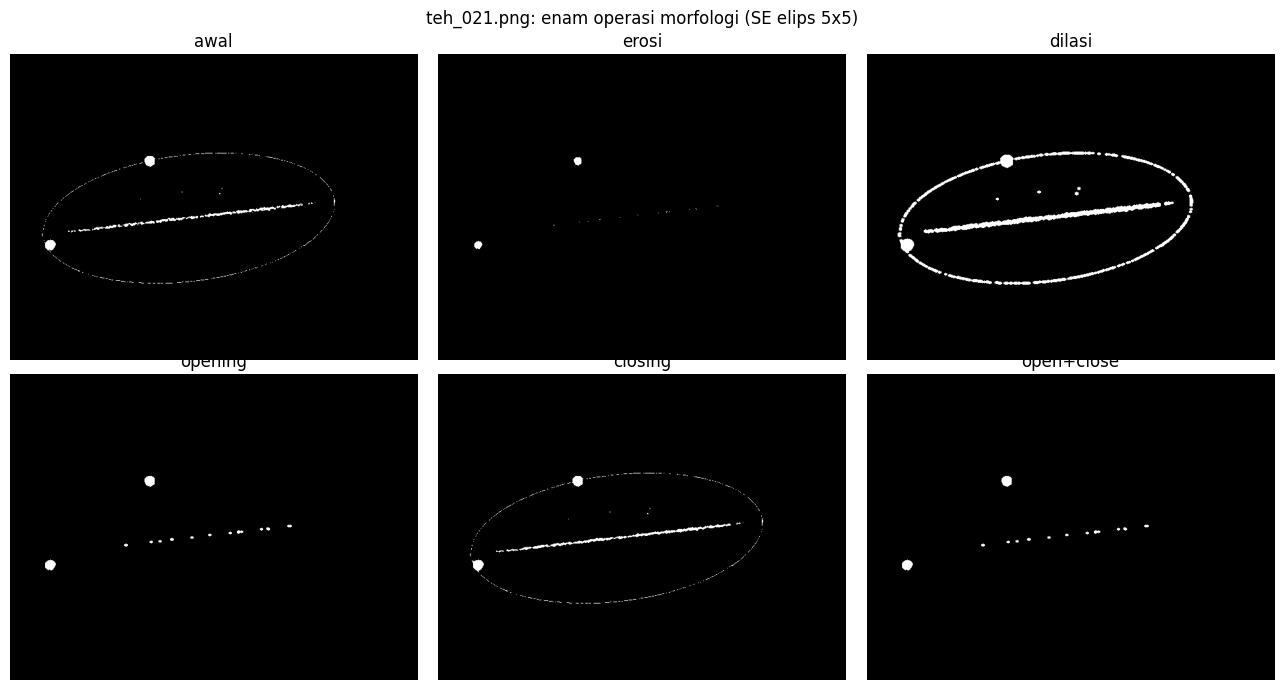

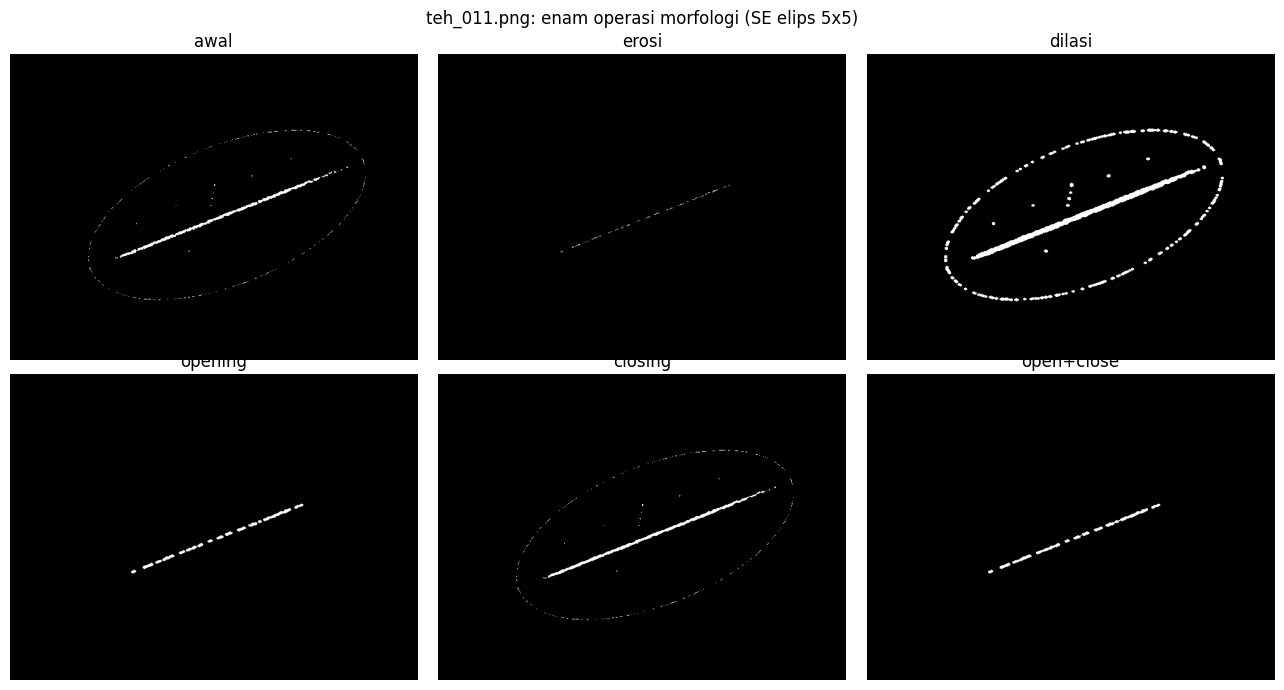

Tabel operasi morfologi:
      citra    operasi  komponen  piksel   IoU
teh_021.png       awal       213    2122 0.145
teh_021.png      erosi        15     261 0.419
teh_021.png     dilasi        32    7775 0.049
teh_021.png    opening        13     667 0.431
teh_021.png    closing       193    2254 0.141
teh_021.png open+close        13     667 0.431
teh_011.png       awal       169    1757 0.000
teh_011.png      erosi        45     120 0.000
teh_011.png     dilasi        72    6280 0.000
teh_011.png    opening        15     927 0.000
teh_011.png    closing       165    1854 0.000
teh_011.png open+close         9     961 0.000


In [3]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1


def SE(k, bentuk=cv2.MORPH_ELLIPSE):
    return cv2.getStructuringElement(bentuk, (k, k))


def operasi(b, se):
    return {"awal": b, "erosi": cv2.erode(b, se), "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
                                           cv2.MORPH_CLOSE, se)}


baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    citra, _, mb_i = muat(nama)
    pra_i = praproses(citra, PARAM)
    b0 = bercak_awal(pra_i, mask_daun_awal(pra_i), kanal=2, k=4.0)
    hasil_operasi = operasi(b0, SE(5))
    for nama_op, m in hasil_operasi.items():
        baris.append([nama, nama_op, jumlah_komponen(m), int((m > 0).sum()), iou(m, mb_i)])
    fig, ax = plt.subplots(2, 3, figsize=(13, 7))
    for sumbu, (nama_op, m) in zip(ax.ravel(), hasil_operasi.items()):
        sumbu.imshow(m, cmap="gray")
        sumbu.set_title(nama_op)
        sumbu.axis("off")
    fig.suptitle(f"{nama}: enam operasi morfologi (SE elips 5x5)")
    fig.tight_layout()
    nomor = nama.removesuffix(".png")
    fig.savefig(hasil_dir / f"p6_operasi_{nomor}.png", dpi=150, bbox_inches="tight")
    plt.show()
operasi_df = pd.DataFrame(
    baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]
)
print("Tabel operasi morfologi:")
print(operasi_df.round(3).to_string(index=False))
operasi_df.to_csv(hasil_dir / "p6_operasi_morfologi.csv", index=False)

### Langkah 3.4–3.6 — Eksperimen SE dan gradien morfologi

                       galat_jumlah    IoU
bentuk  ukuran kelas                      
elips   3      berat          12.95  0.603
               ringan         10.65  0.222
               sehat          10.35    NaN
        5      berat           2.90  0.627
               ringan          2.85  0.334
               sehat           3.35    NaN
        7      berat           0.55  0.644
               ringan          0.75  0.437
               sehat           0.45    NaN
persegi 3      berat           7.10  0.608
               ringan          6.35  0.249
               sehat           5.30    NaN
        5      berat           1.55  0.635
               ringan          1.45  0.417
               sehat           1.60    NaN
        7      berat           0.65  0.617
               ringan          0.95  0.343
               sehat           0.00    NaN
silang  3      berat          12.95  0.603
               ringan         10.65  0.222
               sehat          10.35    NaN
        5  

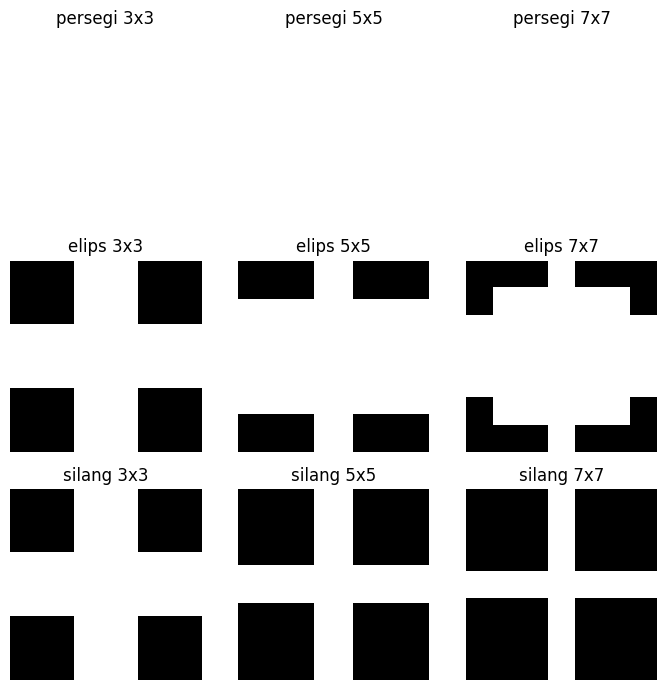

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.857     0.728
gelap                          0.983     0.687
kontras_rendah                 0.190     0.866
normal                         0.976     0.684
terang                         0.935     0.696


In [4]:

bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    citra, _, mb_i = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    b0 = bercak_awal(pra_i, mask_daun_awal(pra_i), kanal=2)
    for k in [3, 4, 6]:
        b_k = bercak_awal(pra_i, mask_daun_awal(pra_i), kanal=2, k=k)
        for nama_b, kode_b in bentuk.items():
            for ukuran in [3, 5, 7]:
                se = SE(ukuran, kode_b)
                m = cv2.morphologyEx(cv2.morphologyEx(b_k, cv2.MORPH_OPEN, se),
                                     cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nama_b, ukuran,
                              abs(jumlah_komponen(m) - jumlah_komponen(mb_i)),
                              iou(m, mb_i) if mb_i.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks[eks.k == 4].groupby(["bentuk", "ukuran", "kelas"])[["galat_jumlah", "IoU"]].mean().round(3))
eks.to_csv(hasil_dir / "p6_eksperimen_se.csv", index=False)

fig, ax = plt.subplots(3, 3, figsize=(7, 7))
for i, (nama_b, kode_b) in enumerate(bentuk.items()):
    for j, ukuran in enumerate([3, 5, 7]):
        ax[i, j].imshow(SE(ukuran, kode_b), cmap="gray", vmin=0, vmax=1)
        ax[i, j].set_title(f"{nama_b} {ukuran}x{ukuran}"); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig(hasil_dir / "p6_panel_se.png", dpi=150); plt.show()

baris = []
for _, d in label.iterrows():
    citra, md_i, _ = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    grad = cv2.morphologyEx(mask_daun_awal(pra_i), cv2.MORPH_GRADIENT, SE(3))
    canny = tepi_canny(cv2.cvtColor(pra_i, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md_i)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
gradien = pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
print(gradien.groupby("kondisi").mean().round(3))
gradien.to_csv(hasil_dir / "p6_gradien_morfologi.csv", index=False)


## Bagian 4 — Komponen terhubung dan pengukuran bercak

Komponen konektivitas 4: 10
Komponen konektivitas 8: 10
   label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek      cx  \
0      1      117     22.39        38.38       1.00         1.09  434.89   
1      2      128     24.50        39.80       1.02         1.00  431.17   
2      3      217     41.54        53.46       0.95         1.00  255.97   
3      4      177     33.88        86.08       0.30         6.78  457.66   
4      5      196     37.52        97.74       0.26         8.20  417.35   
5      6      153     29.29        89.74       0.24         7.32  375.61   
6      7       78     14.93        30.49       1.05         1.12  519.00   
7      8      574    109.87       109.15       0.61         1.55  402.36   
8      9      823    157.53       370.23       0.08        27.13  276.60   
9     10      174     33.30        49.21       0.90         1.10  169.32   

       cy  
0  176.81  
1  208.86  
2  216.97  
3  225.29  
4  244.03  
5  263.21  
6  263.29  
7  284.02  

Tabel 11:
                  aturan  galat_jumlah_berat  galat_jumlah_ringan  galat_jumlah_sehat  daun_sehat_dengan_bercak_palsu
        luas + kebulatan                1.15                 1.40                1.45                              10
luas + kebulatan + rasio                0.80                 1.10                0.40                               3
              luas >= 20                1.70                 1.95                2.50                              10
            tanpa saring                2.90                 2.85                3.35                              10


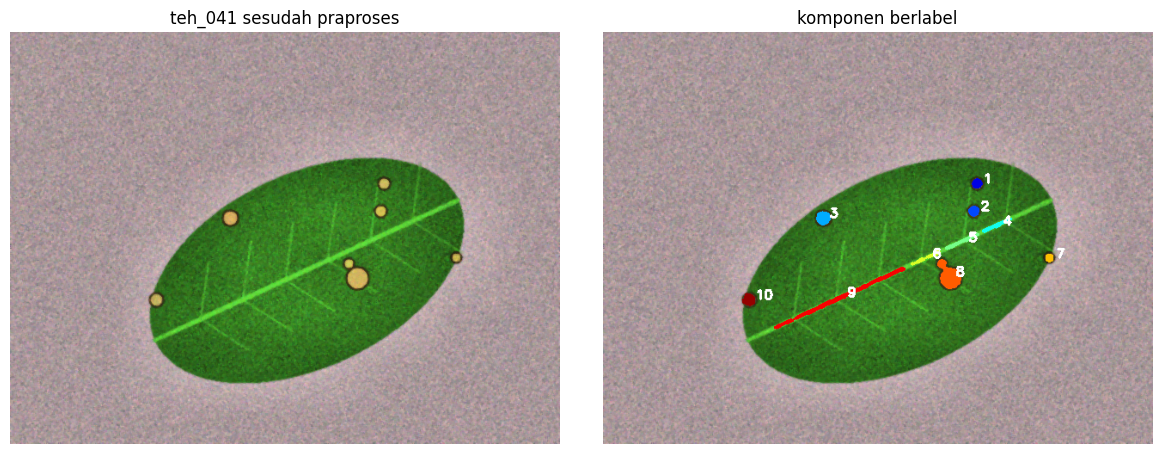

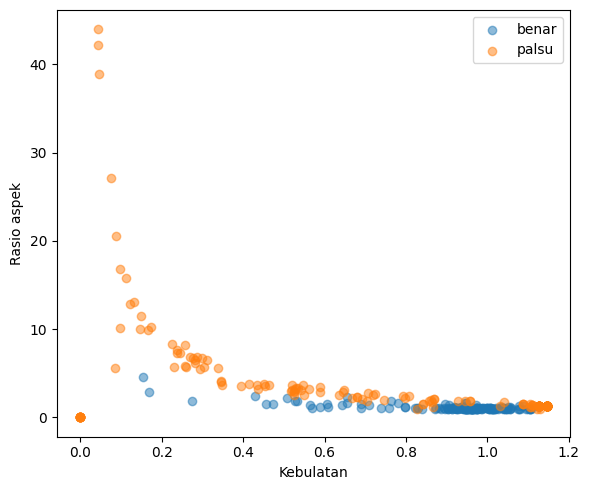

In [5]:
MM_PER_PX = 0.4375


def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        area = int(st[i, cv2.CC_STAT_AREA])
        keliling = float(cv2.arcLength(kontur[0], True))
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * area / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, area, area * MM_PER_PX ** 2, keliling, kebulatan, rasio,
                      cen[i][0], cen[i][1]])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan",
             "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl


def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos


citra, md_i, mb_i = muat("teh_041.png")
pra_i = praproses(citra, PARAM)
b0 = bercak_awal(pra_i, mask_daun_awal(pra_i))
bersih = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
tabel_kom, lbl = ukur_komponen(bersih)
print("Komponen konektivitas 4:", jumlah_komponen(bersih, 4))
print("Komponen konektivitas 8:", jumlah_komponen(bersih, 8))
print(tabel_kom.round(2))
tabel_kom.to_csv(hasil_dir / "p6_ukuran_teh041.csv", index=False)

warna = cv2.applyColorMap((lbl * (255 // max(int(lbl.max()), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_i[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_i, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99),
          "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris, titik = [], []
for _, d in label.iterrows():
    citra, _, mb_i = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    b = bercak_awal(pra_i, mask_daun_awal(pra_i))
    b = cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    tabel_b, lbl_b = ukur_komponen(b)
    for _, r in tabel_b.iterrows():
        mask_i = lbl_b == int(r.label)
        overlap = float((mask_i & (mb_i > 0)).sum()) / max(int(mask_i.sum()), 1)
        titik.append([r.kebulatan, r.rasio_aspek, "benar" if overlap > 0.5 else "palsu"])
    for nama_a, (a, bulat, rasio) in aturan.items():
        f, _ = saring(b, a, bulat, rasio)
        baris.append([d.kelas, nama_a, jumlah_komponen(f), jumlah_komponen(mb_i)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
ringkasan = uji.groupby(["aturan", "kelas"]).agg(galat_jumlah=("galat", "mean")).reset_index()
ringkasan = ringkasan.pivot(index="aturan", columns="kelas", values="galat_jumlah").reset_index()
ringkasan = ringkasan.rename(columns={
    "berat": "galat_jumlah_berat", "ringan": "galat_jumlah_ringan",
    "sehat": "galat_jumlah_sehat"
})
palsu = (uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0)
         .groupby("aturan")["palsu"].sum().rename("daun_sehat_dengan_bercak_palsu"))
ringkasan = ringkasan.set_index("aturan").join(palsu).reset_index()
print("Tabel 11:")
print(ringkasan.round(2).to_string(index=False))
ringkasan.to_csv(hasil_dir / "p6_penyaringan.csv", index=False)

titik_df = pd.DataFrame(titik, columns=["kebulatan", "rasio_aspek", "status"])
fig, ax = plt.subplots(figsize=(6, 5))
for status, kelompok in titik_df.groupby("status"):
    ax.scatter(kelompok.kebulatan, kelompok.rasio_aspek, label=status, alpha=0.5)
ax.set_xlabel("Kebulatan")
ax.set_ylabel("Rasio aspek")
ax.legend()
fig.tight_layout()
fig.savefig(hasil_dir / "p6_sebar_luas_kebulatan.png", dpi=150)
plt.show()

## Bagian 5 — Integrasi analisis bercak SIMUTEH

Tabel 12 - akurasi per kondisi:
                akurasi  galat_persen
kondisi                              
bayangan          1.000         0.625
gelap             1.000         0.234
kontras_rendah    0.667         1.017
normal            0.750         0.580
terang            0.750         0.776
Galat absolut rerata persen: 0.646
Korelasi persen: 0.939
Akurasi kelas: 0.833
kelas_prediksi  Bercak Berat  Bercak Ringan  Sehat
kelas_acuan                                       
Bercak Berat              17              3      0
Bercak Ringan              0             15      5
Sehat                      0              2     18


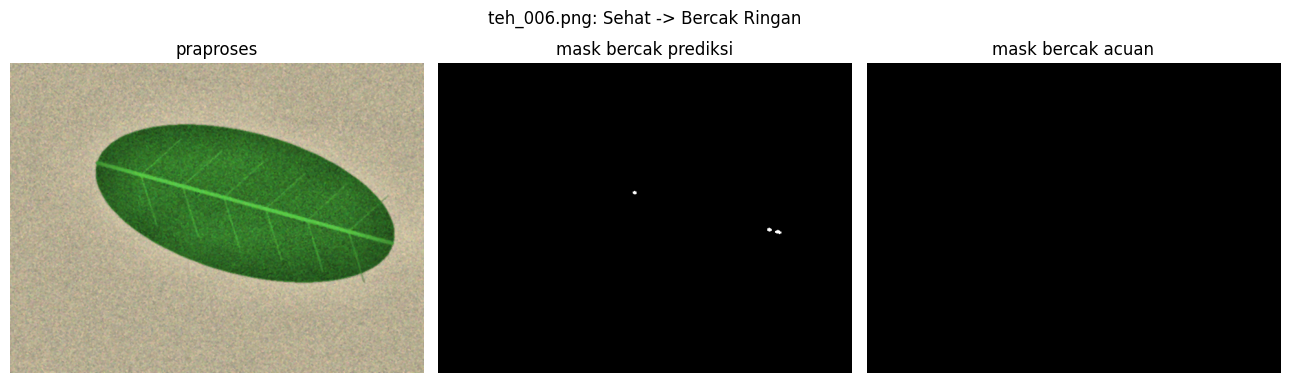

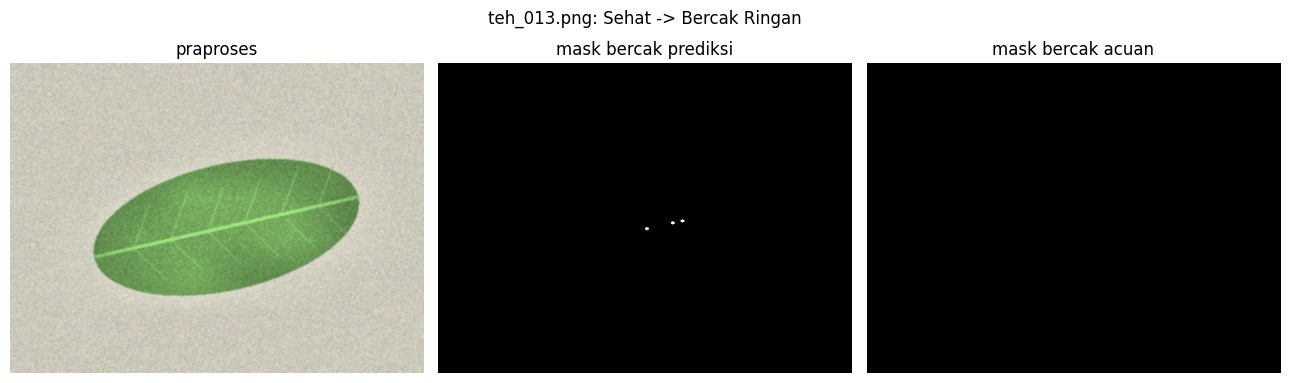

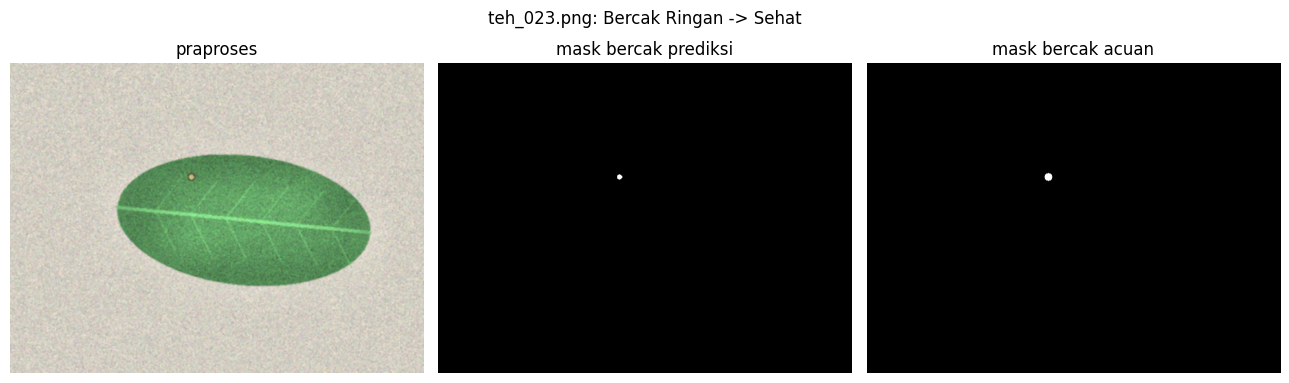

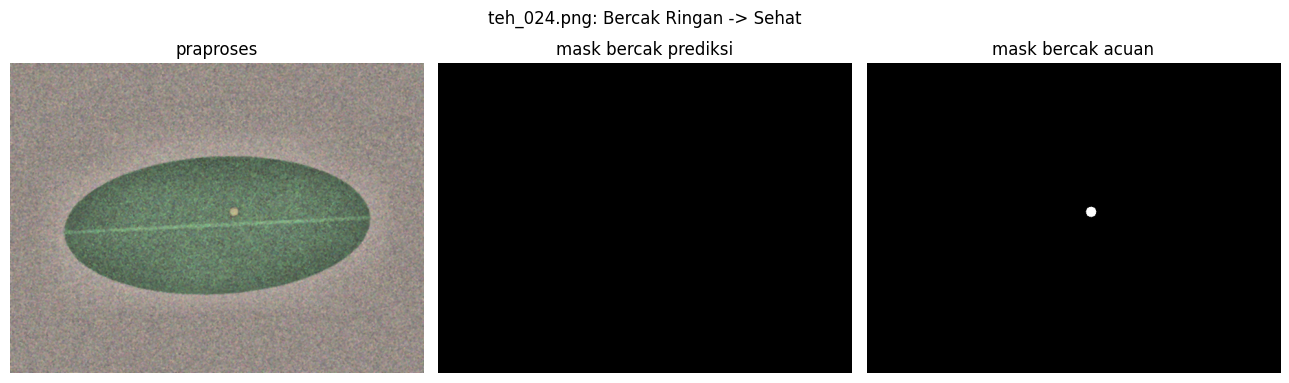

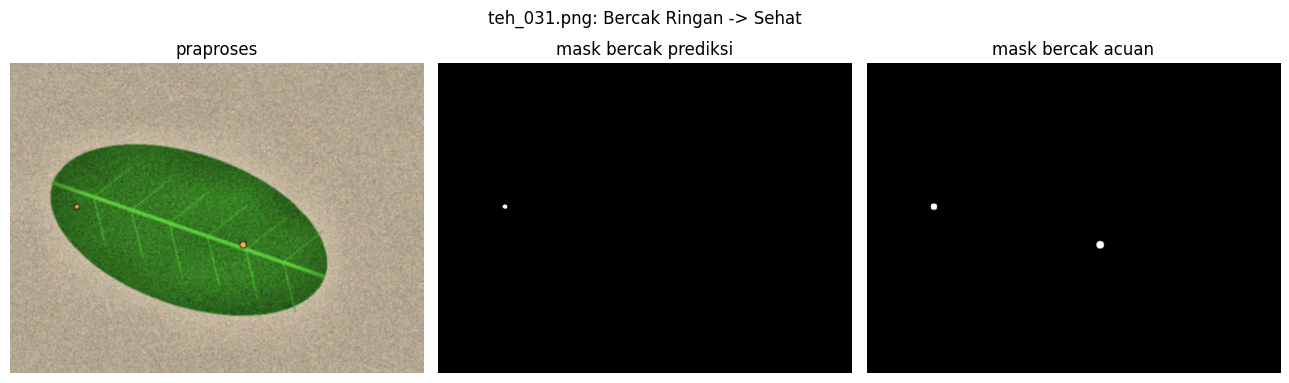

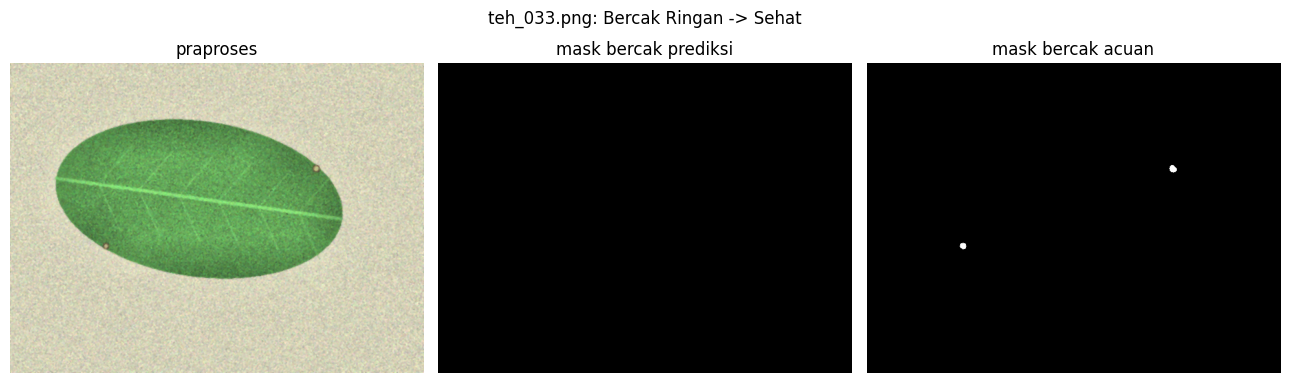

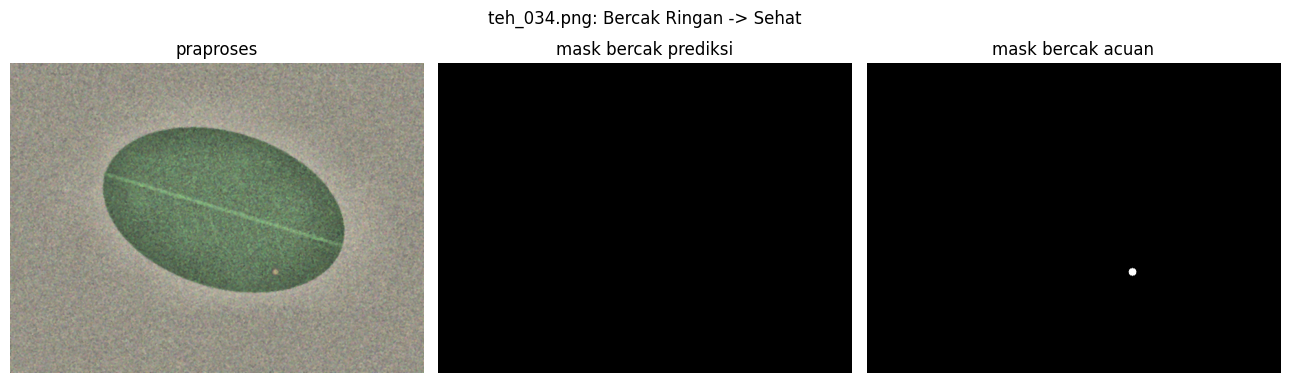

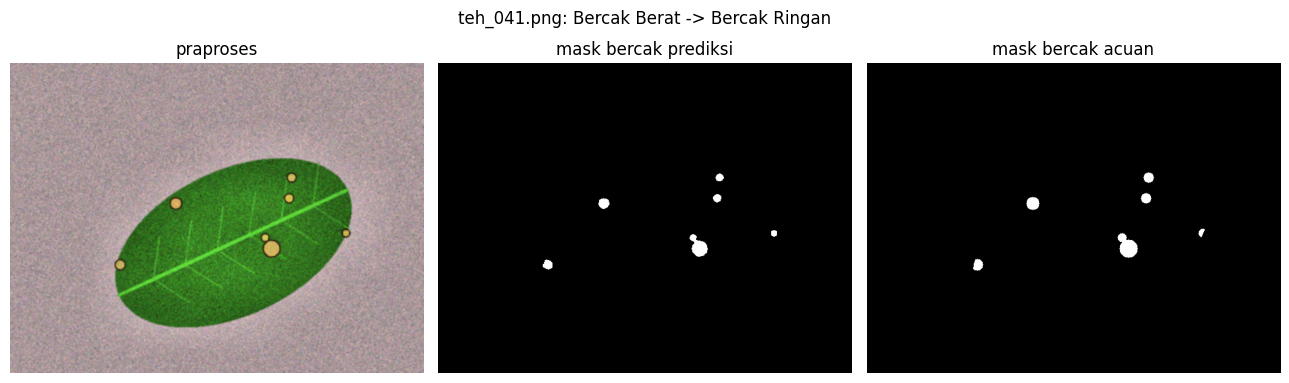

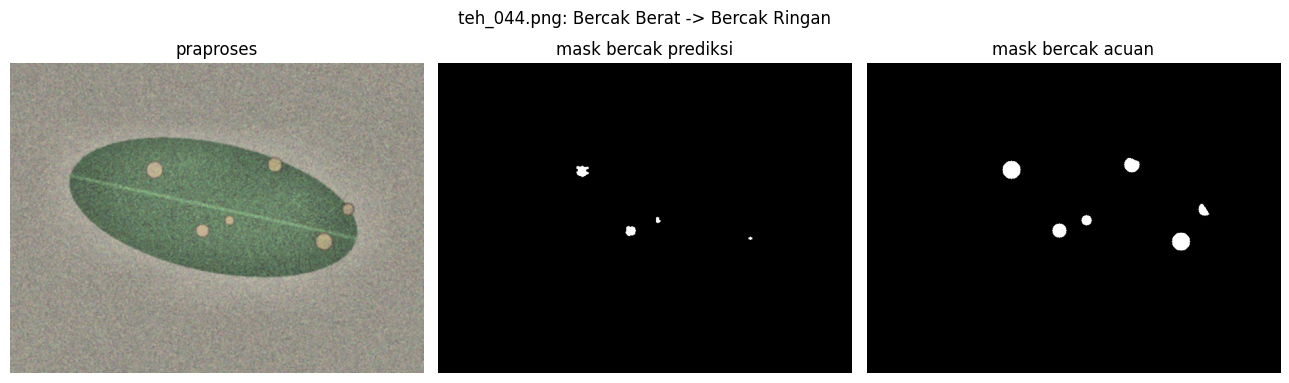

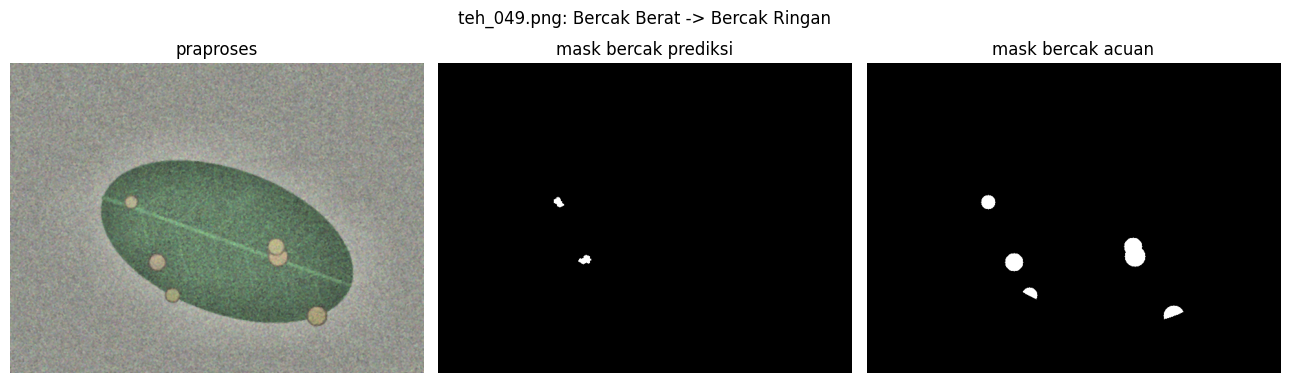

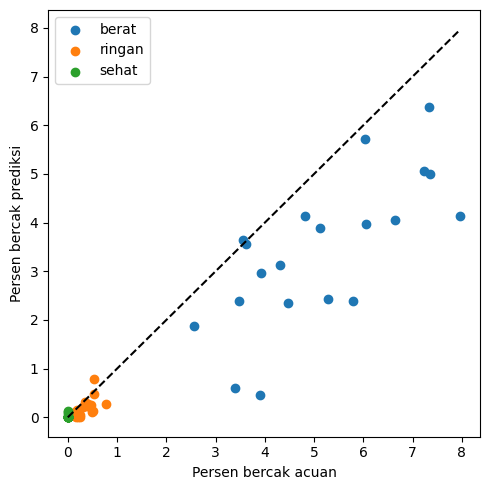

In [6]:
# Langkah 5.5 memakai satu implementasi bersama dari src/bercak.py.
simpan_param(PARAM_BERCAK, hasil_dir / "param_bercak.json")
baris = []
panel = []
for _, d in label.iterrows():
    citra, _, mb_i = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    pred = analisis_daun(pra_i)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak,
                  pred["persen_bercak"], jumlah_komponen(mb_i), pred["jumlah_bercak"],
                  pred["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan",
                                  "persen_prediksi", "jumlah_acuan", "jumlah_prediksi",
                                  "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev["galat_persen"] = (ev.persen_prediksi - ev.persen_acuan).abs()
ev.to_csv(hasil_dir / "p6_evaluasi_bercak.csv", index=False)
print("Tabel 12 - akurasi per kondisi:")
akurasi_kondisi = ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").agg(
    akurasi=("benar", "mean"), galat_persen=("galat_persen", "mean"))
print(akurasi_kondisi.round(3))
akurasi_kondisi.to_csv(hasil_dir / "p6_akurasi_per_kondisi.csv")
print("Galat absolut rerata persen:", ev.galat_persen.mean().round(3))
print("Korelasi persen:", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas:", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi))

for i, (_, salah) in enumerate(ev[ev.kelas_prediksi != ev.kelas_acuan].iterrows(), start=1):
    if salah.kelas == "sehat":
        penyebab = "bercak palsu/derau lolos penyaringan"
    elif salah.kelas_prediksi == "Sehat":
        penyebab = "bercak terlewat atau luas prediksi terlalu kecil"
    else:
        penyebab = "persentase prediksi melewati batas kelas"
    citra_salah, _, mb_salah = muat(salah.nama)
    pred_salah = analisis_daun(praproses(citra_salah, PARAM))
    panel_salah = [praproses(citra_salah, PARAM), pred_salah["mask_bercak"], mb_salah]
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    for sumbu, gambar, judul in zip(
        ax, panel_salah, ["praproses", "mask bercak prediksi", "mask bercak acuan"]
    ):
        sumbu.imshow(cv2.cvtColor(gambar, cv2.COLOR_BGR2RGB) if gambar.ndim == 3 else gambar,
                     cmap=None if gambar.ndim == 3 else "gray")
        sumbu.set_title(judul)
        sumbu.axis("off")
    fig.suptitle(f"{salah.nama}: {salah.kelas_acuan} -> {salah.kelas_prediksi}")
    fig.tight_layout()
    if i <= 3:
        fig.savefig(hasil_dir / f"p6_salah_kelas_{i}.png", dpi=150, bbox_inches="tight")
    plt.show()
    panel.append([salah.nama, salah.kelas_acuan, salah.kelas_prediksi, penyebab])
diagnosis = pd.DataFrame(panel, columns=["nama", "kelas_acuan", "kelas_prediksi", "penyebab"])
diagnosis.to_csv(hasil_dir / "p6_diagnosis_salah_kelas.csv", index=False)

plt.figure(figsize=(5, 5))
for kelas, kelompok in ev.groupby("kelas"):
    plt.scatter(kelompok.persen_acuan, kelompok.persen_prediksi, label=kelas)
plt.plot([0, max(ev.persen_acuan.max(), ev.persen_prediksi.max())],
         [0, max(ev.persen_acuan.max(), ev.persen_prediksi.max())], "k--")
plt.xlabel("Persen bercak acuan")
plt.ylabel("Persen bercak prediksi")
plt.legend()
plt.tight_layout()
plt.savefig(hasil_dir / "p6_persen_prediksi_vs_acuan.png", dpi=150)
plt.show()

Notebook ini menghasilkan tabel evaluasi dan gambar untuk menjawab pertanyaan analisis P3–P5. Interpretasi penyebab kesalahan, risiko ambang, dan keterbatasan dataset sintetis perlu dituliskan pada laporan.